# Model B: XGBoost unit-economics prediction (CloudSense AI)
**Input (spec):** one row per service per day with `cost_usd, active_users, api_requests, transactions, cpu_avg, network_bytes, instance_family, region, resource_tag, provisioning_frequency` (+ optional `instance_count_avg, instance_count_max, cpu_p95, mem_avg, ebs_provisioned_gb, is_promo, is_holiday`). `time_lagged_spend` is computed in code.
**Target:** next-day **cost per API request** (also cost per active user and cost per transaction). **Starting parameters (spec):** `n_estimators=500, max_depth=6, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, reg:squarederror, random_state=42`, then tuned with Optuna and compared on validation. **Baselines:** naive, same-weekday, **Linear Regression**, Ridge, Random Forest, LightGBM.
**SHAP (Model D):** TreeExplainer drivers + risk level + recommended next investigation; **savings are a separate calculation** (`cloudsense/savings.py`).
The logic is in the importable package `cloudsense/unit_economics.py`; synthetic benchmark data by default (real-data block below).

In [1]:
import os, sys, json, warnings, logging, zipfile, time, platform
from pathlib import Path
warnings.filterwarnings("ignore"); logging.basicConfig(level=logging.INFO, format="%(levelname)s | %(message)s")
def _bootstrap():
    try: import cloudsense; return
    except ImportError: pass
    for c in [Path("."), Path(".."), Path("cloudsense_ml"), Path("/content/cloudsense_ml")]:
        if (c / "cloudsense").exists(): sys.path.insert(0, str(c.resolve())); return
    try:                                                         # Colab: upload cloudsense_ml.zip once
        from google.colab import files
        for n, b in files.upload().items(): open(n, "wb").write(b); zipfile.ZipFile(n).extractall(".")
        sys.path.insert(0, str(Path("cloudsense_ml").resolve()))
    except ImportError: raise ImportError("Put the cloudsense/ package folder next to this notebook (or in ../), or on Colab upload cloudsense_ml.zip")
_bootstrap()
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import cloudsense; print("cloudsense", cloudsense.__version__)
def find_data(files):
    for c in ["data", "../data", "cloudsense_ml/data", "/content/data", "/content/cloudsense_ml/data"]:
        if all((Path(c) / f).exists() for f in files): return Path(c)
    try:
        from google.colab import files as cf; Path("data").mkdir(exist_ok=True)
        for n, b in cf.upload().items(): open(Path("data") / n, "wb").write(b)
        return Path("data")
    except ImportError: raise FileNotFoundError(f"Put {files} in ./data")
def make_outputs(tag):
    out = Path(f"outputs_{tag}"); fig = out / "figures"; art = out / "artifacts"
    for p in (fig, art): p.mkdir(parents=True, exist_ok=True)
    caps = {}
    def savefig(name, caption):
        plt.tight_layout(); plt.savefig(fig / f"{name}.png", dpi=105, bbox_inches="tight"); caps[name] = caption; plt.show()
    return out, fig, art, caps, savefig

from cloudsense import unit_economics as ue, savings as sv
from cloudsense.common import jdump
import shap
OUT, FIG, ART, CAPS, savefig = make_outputs("model_b"); DATA = find_data(["B_unit_economics_daily.csv"]); print("data:", DATA)

cloudsense 1.0.0


data: ../data


## 1. Load and validate

In [2]:
df = pd.read_csv(DATA / "B_unit_economics_daily.csv", parse_dates=["date"])
# ---- REAL DATA (optional): build the same frame from your AWS account + your own KPI table (see cloudsense/collectors/pipeline.py: build_model_b_frame)
# from cloudsense.collectors import get_session; from cloudsense.collectors.pipeline import build_model_b_frame; from cloudsense.collectors.kpi import load_kpi_csv
# s = get_session(profile="cloudsense-readonly", region="ap-south-1")
# df = build_model_b_frame(s.client("ce", region_name="us-east-1"), s.client("cloudwatch"), s.client("autoscaling"), SERVICES, "2025-10-01", "2026-10-01", load_kpi_csv("kpis.csv"), cost_tag_key="service")
clean, dq = ue.validate_b(df); jdump(dq, OUT / "data_quality.json")
print(json.dumps({k: v for k, v in dq.items() if k != "date_gaps"}, indent=1)); print("core columns:", ue.CORE_B); print("optional present:", dq["optional_columns_present"])

{
 "rows": 8032,
 "services": [
  "analytics",
  "auth",
  "cart_checkout",
  "catalog",
  "media",
  "notifications",
  "payments",
  "search"
 ],
 "date_range": [
  "2024-01-01",
  "2026-09-30"
 ],
 "negatives": 0,
 "cpu_over_100": 0,
 "zero_requests": 0,
 "zero_users": 0,
 "zero_transactions_share": 0.75,
 "cpu_nan": 30,
 "optional_columns_present": [
  "instance_count_avg",
  "instance_count_max",
  "cpu_p95",
  "mem_avg",
  "ebs_provisioned_gb",
  "is_promo",
  "is_holiday"
 ]
}
core columns: ['date', 'service', 'cost_usd', 'active_users', 'api_requests', 'transactions', 'cpu_avg', 'network_bytes', 'instance_family', 'region', 'resource_tag', 'provisioning_frequency']
optional present: ['instance_count_avg', 'instance_count_max', 'cpu_p95', 'mem_avg', 'ebs_provisioned_gb', 'is_promo', 'is_holiday']


## 2. EDA

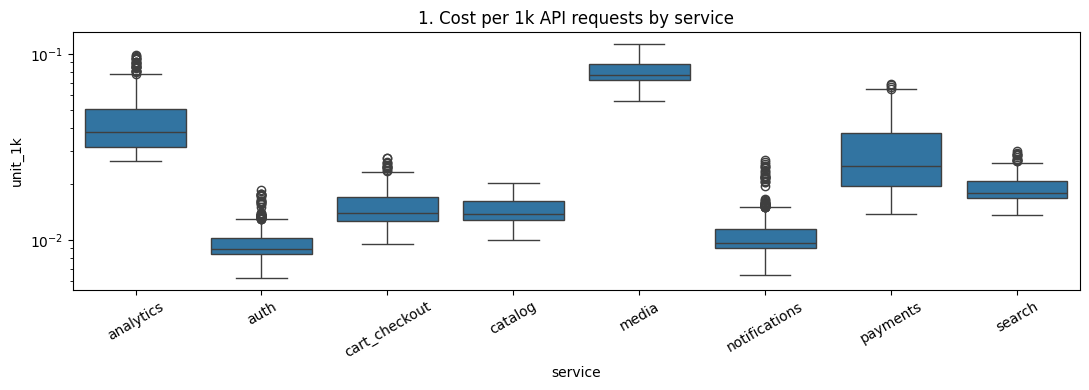

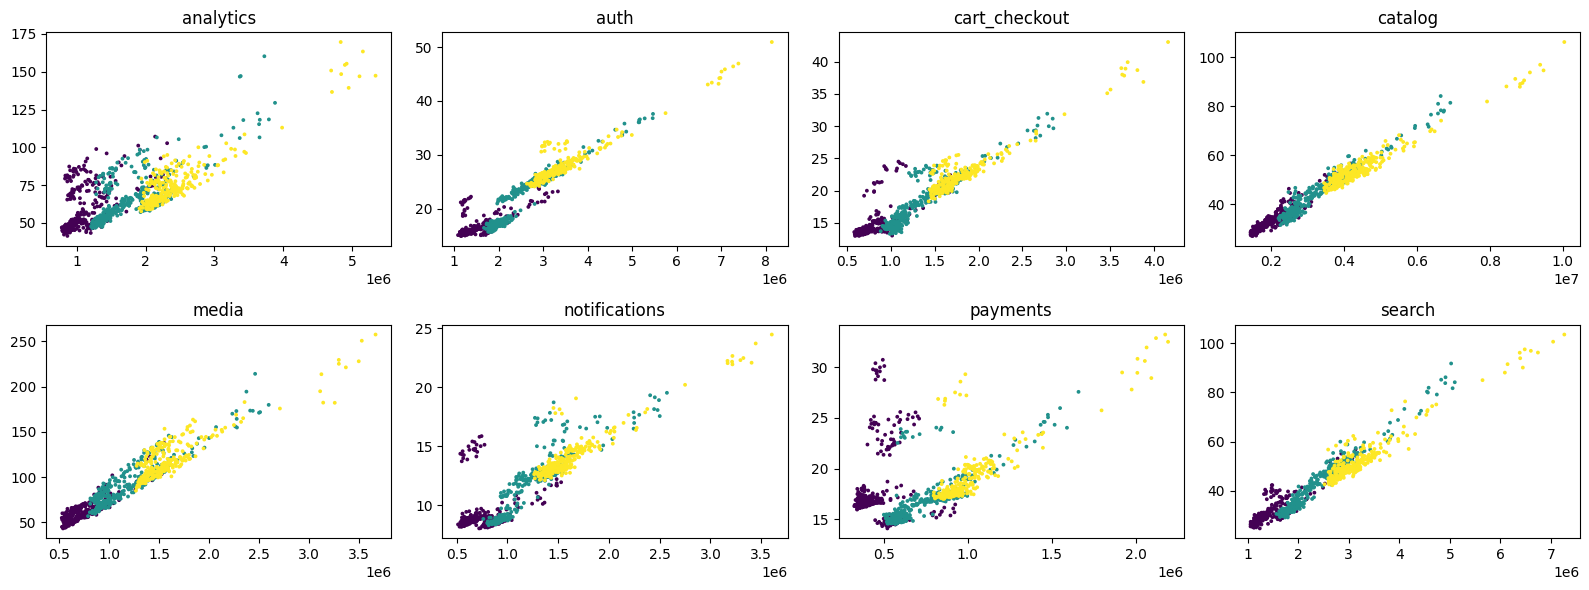

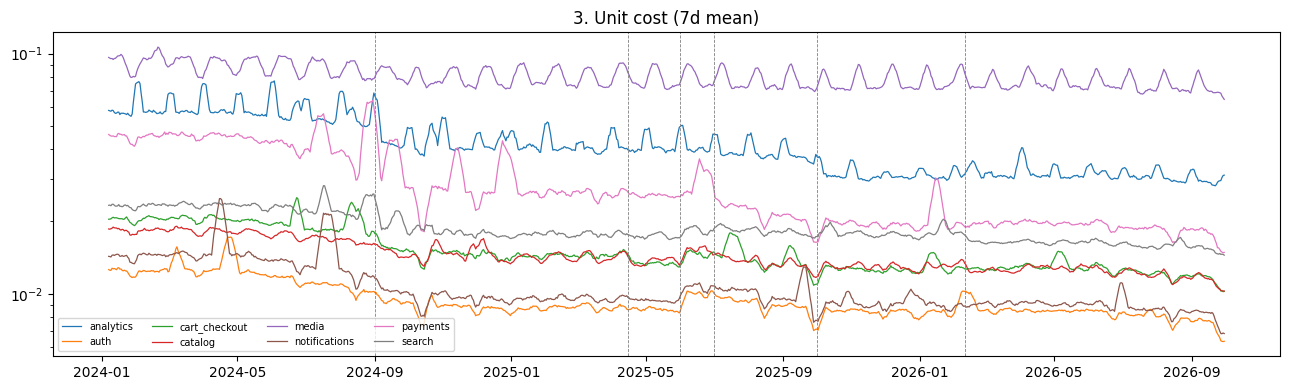

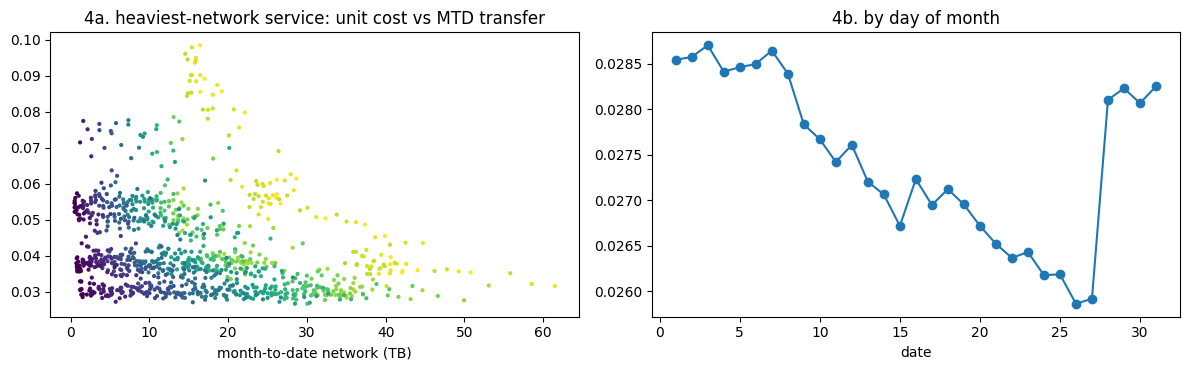

share of days flagged as idle-capacity per service: {'analytics': 0.029, 'auth': 0.046, 'cart_checkout': 0.061, 'catalog': 0.043, 'media': 0.063, 'notifications': 0.059, 'payments': 0.063, 'search': 0.038}


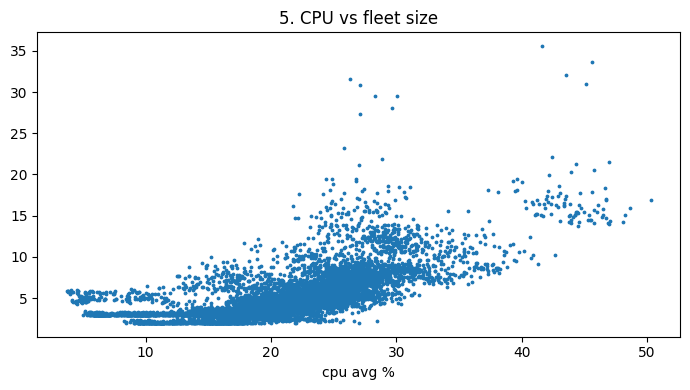

relative unit cost: weekend 1.062 | month-end(>=28) 1.097 | promo {0: 1.097, 1: 0.942}
NaN pattern: {'cpu_avg': 30, 'cpu_p95': 30} | zero-transaction share (structural): 0.75


533

In [3]:
E = clean.assign(unit_1k=clean.cost_usd / clean.api_requests * 1000, per_user_1k=clean.cost_usd / clean.active_users * 1000)
EV = {"2024-09-01": "Savings Plan", "2025-04-15": "m5->m6g", "2025-06-01": "RDS resize", "2025-07-01": "v3", "2025-10-01": "right-size", "2026-02-10": "caching"}     # documented in the synthetic benchmark
fig, ax = plt.subplots(figsize=(11, 4)); sns.boxplot(data=E, x="service", y="unit_1k", ax=ax); ax.set_yscale("log"); ax.tick_params(axis="x", rotation=30); ax.set_title("1. Cost per 1k API requests by service"); savefig("01_unit_cost", "Unit-cost distributions")
fig, axs = plt.subplots(2, 4, figsize=(16, 6))
for ax, (k, g) in zip(axs.ravel(), E.groupby("service")): ax.scatter(g.api_requests, g.cost_usd, s=3, c=g.date.dt.year); ax.set_title(k)
savefig("02_cost_vs_requests", "Fixed + variable cost structure")
fig, ax = plt.subplots(figsize=(13, 4))
for k, g in E.groupby("service"): ax.plot(g.date, g.unit_1k.rolling(7).mean(), label=k, lw=.9)
for d_ in EV: ax.axvline(pd.Timestamp(d_), color="grey", ls="--", lw=.6)
ax.set_yscale("log"); ax.legend(ncol=4, fontsize=7); ax.set_title("3. Unit cost (7d mean)"); savefig("03_unit_cost_time", "Unit cost over time")
daily = E.groupby("date").network_bytes.sum(); mtd = daily.groupby(daily.index.to_period("M")).cumsum(); m_ = E[E.service == E.service.iloc[E.groupby("service").network_bytes.sum().values.argmax()]].copy(); m_["mtd"] = m_.date.map(mtd)
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8)); axs[0].scatter(m_.mtd / 1e12, m_.unit_1k, s=4, c=m_.date.dt.day); axs[0].set_xlabel("month-to-date network (TB)"); axs[0].set_title("4a. heaviest-network service: unit cost vs MTD transfer"); E.groupby(E.date.dt.day).unit_1k.mean().plot(ax=axs[1], marker="o"); axs[1].set_title("4b. by day of month"); savefig("04_tier_effect", "Tiered transfer pricing effect")
if "instance_count_avg" in E:
    i_ = E.assign(rm=E.groupby("service").instance_count_avg.transform(lambda s: s.rolling(28, min_periods=14).median()), cm=E.groupby("service").cpu_avg.transform("median")); i_["idle"] = (i_.instance_count_avg > i_.rm * 1.15) & (i_.cpu_avg < i_.cm * .85)
    print("share of days flagged as idle-capacity per service:", i_.groupby("service").idle.mean().round(3).to_dict())
fig, ax = plt.subplots(figsize=(7, 4)); ax.scatter(E.cpu_avg, E.instance_count_avg if "instance_count_avg" in E else E.provisioning_frequency, s=3); ax.set_xlabel("cpu avg %"); ax.set_title("5. CPU vs fleet size"); savefig("05_utilisation", "Utilisation vs fleet size")
E2 = E.assign(rel=E.unit_1k / E.groupby("service").unit_1k.transform("median"), dow=E.date.dt.dayofweek); print("relative unit cost: weekend", round(E2[E2.dow >= 5].rel.mean(), 3), "| month-end(>=28)", round(E2[E2.date.dt.day >= 28].rel.mean(), 3), "| promo", E2.groupby("is_promo").rel.mean().round(3).to_dict() if "is_promo" in E2 else "n/a")
print("NaN pattern:", clean.isna().sum()[lambda s: s > 0].to_dict(), "| zero-transaction share (structural):", dq["zero_transactions_share"])
open(OUT / "eda_summary.md", "w").write("""# EDA -> decisions
Unit cost differs by service -> service/instance_family/region/tag features and per-service comparison.
Cost = fixed + variable -> requests_per_instance, utilisation, lag features.
Month-to-date network volume drives a tier sawtooth -> mtd_network_bytes, tier1_share_used.
Weekend/month-end/promo effects -> next-day calendar features (known in advance).
CPU gaps imputed from TRAIN medians (flagged); transactions structurally zero for most services -> separate per-transaction model; zero denominators excluded.
""")

## 3. Train (time split 70/15/15, baselines, Optuna, selection on validation, refit, ONE test evaluation)

In [4]:
t0 = time.time(); o = ue.train_unit_economics(df, out_dir=ART / "model_registry" / "xgb_unit_economics", progress=print); print(f"done in {time.time()-t0:.0f}s | deployed: {o['choice']} | trees: {o['n_trees']} | params: {o['params']}")
print("split:", o["split"]); R = o["results"]; R[R.split == "val"].round(5)

rows train/val/test: 5400/1208/1200 | split 2025-12-02 / 2026-05-02


validation MAE: {'naive_today': 0.00126, 'naive_same_weekday': 0.00218, 'linear_regression': 0.00139, 'ridge': 0.00139, 'random_forest': 0.00093, 'lightgbm': 0.00095, 'xgb_spec_params': 0.0009, 'xgb_tuned': 0.00098, 'xgb_tuned_per_service': 0.00108} -> deploy xgb_spec_params


done in 116s | deployed: xgb_spec_params | trees: 144 | params: {'max_depth': 6, 'learning_rate': 0.05, 'subsample': 0.8, 'colsample_bytree': 0.8, 'objective': 'reg:squarederror', 'random_state': 42}
split: {'train_end': '2025-12-02', 'val_end': '2026-05-02'}


,model,split,MAE,RMSE,R2,MAPE,sMAPE
0,naive_today,val,0.00126,0.00243,0.98714,4.94386,4.93230
2,naive_same_weekday,val,0.00218,0.00465,0.95298,7.21540,7.17180
4,linear_regression,val,0.00139,0.00225,0.98900,6.73918,6.96923
6,ridge,val,0.00139,0.00225,0.98897,6.57068,6.73279
8,random_forest,val,0.00093,0.00162,0.99427,3.90801,3.87526
10,lightgbm,val,0.00095,0.00162,0.99430,4.18759,4.16807
12,xgb_spec_params,val,0.00090,0.00154,0.99483,3.92427,3.88776
14,xgb_tuned,val,0.00098,0.00162,0.99428,4.36384,4.31820
16,xgb_tuned_per_service,val,0.00108,0.00162,0.99431,5.39301,5.25906


## 4. Evaluation (test)

TEST (target scaled to USD per 1,000 requests; R2/MAPE are scale-free):
                           MAE     RMSE       R2     MAPE    sMAPE
model                                                             
naive_today            0.00117  0.00228  0.98805  4.73861  4.72655
naive_same_weekday     0.00193  0.00416  0.96007  6.86333  6.76148
linear_regression      0.00144  0.00234  0.98741  7.38457  7.58372
ridge                  0.00143  0.00236  0.98714  7.17482  7.31650
random_forest          0.00105  0.00174  0.99302  4.97710  4.84723
lightgbm               0.00105  0.00175  0.99295  5.14335  5.01376
xgb_spec_params        0.00100  0.00162  0.99392  4.91233  4.78644
xgb_tuned              0.00103  0.00162  0.99393  5.51172  5.33403
xgb_tuned_per_service  0.00154  0.00206  0.99021  9.33865  8.72183
xgb_final_refit        0.00095  0.00166  0.99365  4.56854  4.45713

XGBoost(final) improvement in MAE over baselines  [mean, 2.5%, 97.5%]  (positive = XGBoost better):
                       

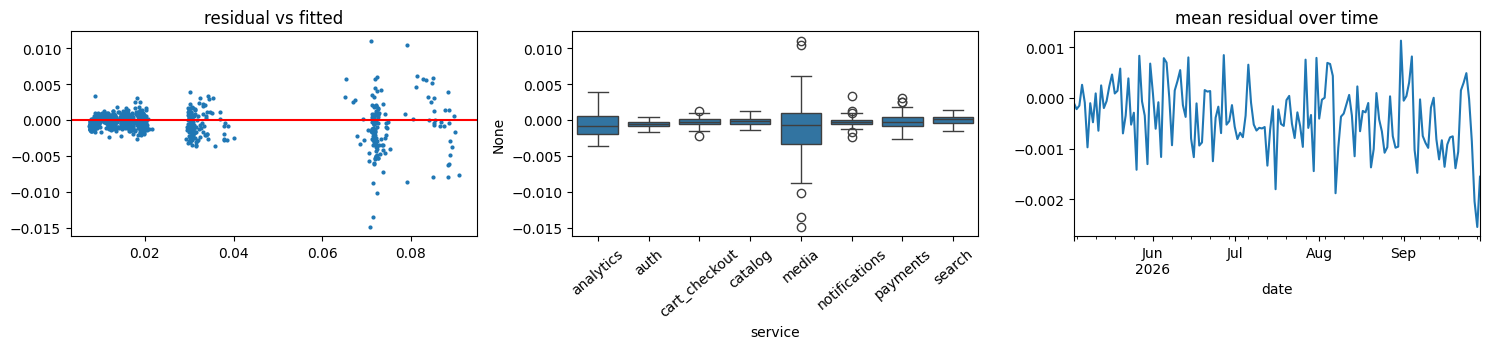


worst 5 predictions:
       date service  y_req     pf  abs_err
2026-09-27   media 0.0559 0.0708   0.0149
2026-09-28   media 0.0580 0.0715   0.0135
2026-07-31   media 0.0820 0.0709   0.0111
2026-08-31   media 0.0897 0.0792   0.0105
2026-07-16   media 0.0621 0.0723   0.0101

secondary targets (test): {'cost_per_active_user': {'xgb_MAE': 0.021, 'naive_MAE': 0.02022, 'excluded_rows': 0}, 'cost_per_transaction': {'xgb_MAE': 9e-05, 'naive_MAE': 0.0001, 'excluded_rows': 0}}


In [5]:
tt = R[R.split == "test"].set_index("model")[["MAE", "RMSE", "R2", "MAPE", "sMAPE"]].round(5); print("TEST (target scaled to USD per 1,000 requests; R2/MAPE are scale-free):"); print(tt)
print("\nXGBoost(final) improvement in MAE over baselines  [mean, 2.5%, 97.5%]  (positive = XGBoost better):"); print(pd.DataFrame(o["bootstrap"], index=["mean", "lo", "hi"]).T.round(6))
best_mape = tt.MAPE.idxmin(); print(f"\nhonesty check -> lowest test MAPE: {best_mape} ({tt.MAPE.min():.2f}%); lowest MAE: {tt.MAE.idxmin()}")
T = o["test_frame"].assign(abs_err=lambda d: (d.y_req - d.pf).abs(), ape=lambda d: (d.y_req - d.pf).abs() / d.y_req * 100); print("\nby service:\n", T.groupby("service")[["abs_err", "ape"]].mean().round(4))
print("weekend-next-day:", T.groupby("next_is_weekend").abs_err.mean().round(5).to_dict(), "| month-end:", T.groupby("next_is_month_end").abs_err.mean().round(5).to_dict())
fig, axs = plt.subplots(1, 3, figsize=(15, 3.6)); axs[0].scatter(T.pf, T.y_req - T.pf, s=4); axs[0].axhline(0, c="r"); axs[0].set_title("residual vs fitted"); sns.boxplot(x="service", y=T.y_req - T.pf, data=T, ax=axs[1]); axs[1].tick_params(axis="x", rotation=40); T.groupby("date").apply(lambda g: (g.y_req - g.pf).mean()).plot(ax=axs[2]); axs[2].set_title("mean residual over time"); savefig("10_residuals", "Residual analysis")
print("\nworst 5 predictions:\n", T.sort_values("abs_err", ascending=False).head(5)[["date", "service", "y_req", "pf", "abs_err"]].round(4).to_string(index=False))
print("\nsecondary targets (test):", {k: dict(xgb_MAE=round(v["xgb"]["MAE"], 5), naive_MAE=round(v["naive"]["MAE"], 5), excluded_rows=v["excluded_rows"]) for k, v in o["secondary"].items()})

## 5. Explainability (Model D): SHAP + risk level + recommended next investigation

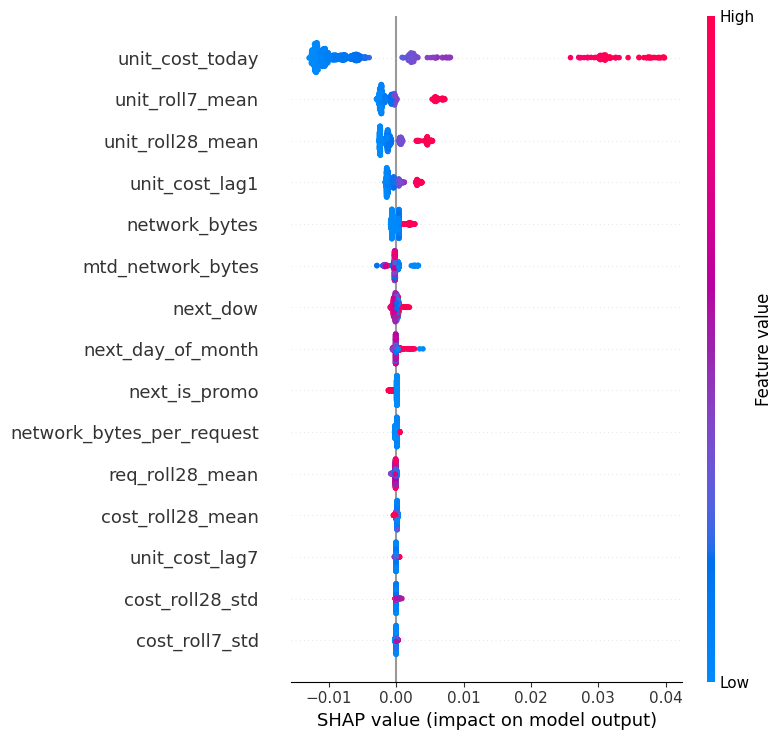

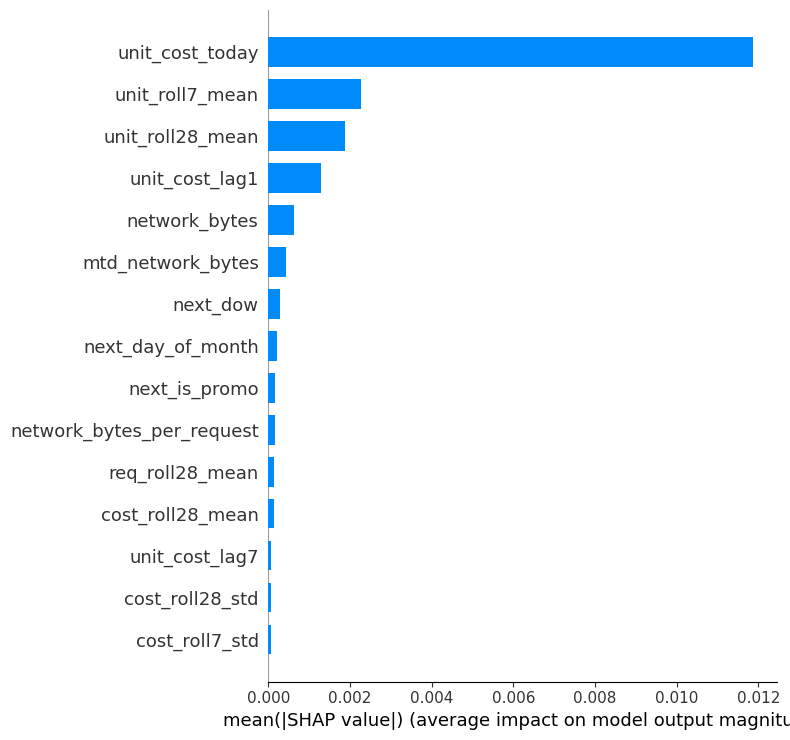

<Figure size 640x480 with 0 Axes>

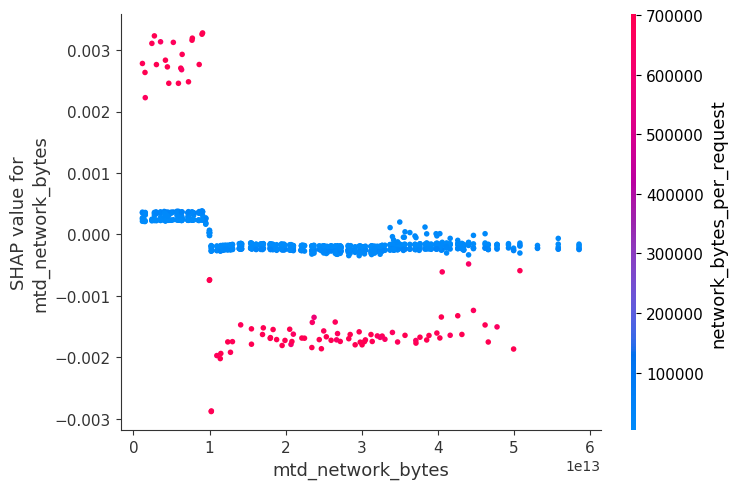

<Figure size 640x480 with 0 Axes>

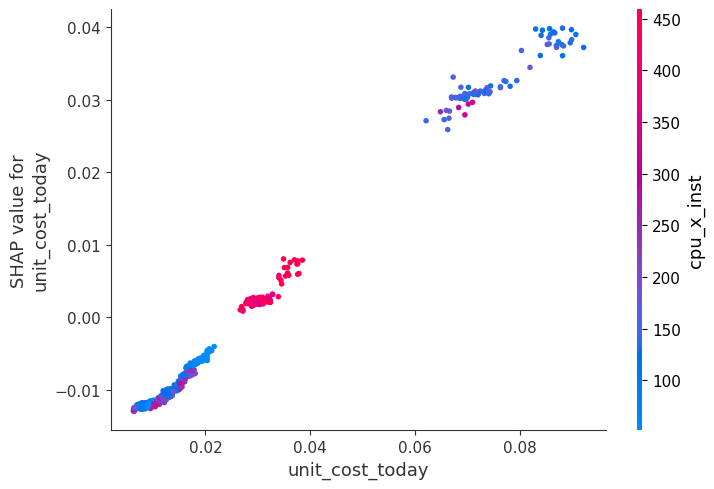

<Figure size 640x480 with 0 Axes>

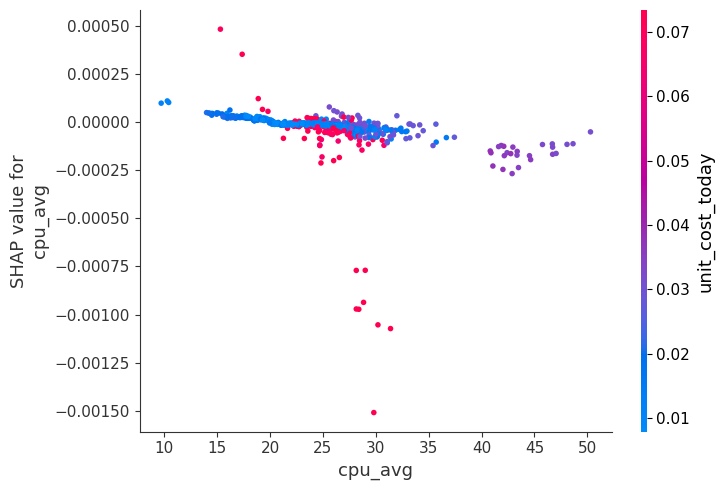

<Figure size 640x480 with 0 Axes>

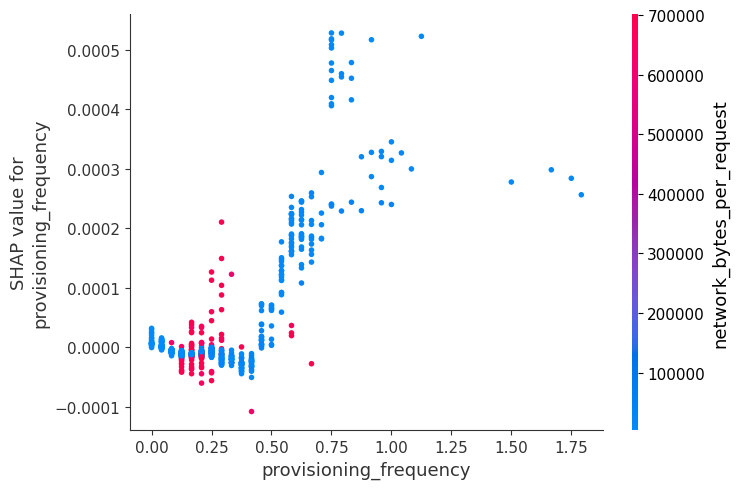

rank correlation SHAP vs permutation importance: 0.76 | top SHAP features: {'unit_cost_today': 0.011900000274181366, 'unit_roll7_mean': 0.002300000051036477, 'unit_roll28_mean': 0.0019000000320374966, 'unit_cost_lag1': 0.0013000000035390258, 'network_bytes': 0.0006000000284984708}



[LOW] analytics -1.7% vs 7-day mean | next step: Cost pattern follows the calendar (weekend/month-end/promo): confirm it is the expected seasonal effect.
   analytics: predicted cost per 1k requests 0.0306 (-1.7% vs its realised 7-day mean). Compared with its last 7 days, the biggest changes in model drivers: unit_cost_today (lowers it); next_is_promo (raises it); next_day_of_month (lowers it); next_dow (lowers it). Model attribution only - not causal proof and not a savings estimate.

[HIGH] auth +38.9% vs 7-day mean | next step: Cost pattern follows the calendar (weekend/month-end/promo): confirm it is the expected seasonal effect.
   auth: predicted cost per 1k requests 0.0088 (+38.9% vs its realised 7-day mean). Compared with its last 7 days, the biggest changes in model drivers: next_is_promo (raises it); unit_cost_today (raises it); next_dow (lowers it); instance_count_avg (raises it). Model attribution only - not causal proof and not a savings estimate.

[MEDIUM] cart_checkout 

In [6]:
feats = o["features"]; Xs = T[feats].sample(min(800, len(T)), random_state=42); ex = shap.TreeExplainer(o["model"]); sv_ = ex.shap_values(Xs)
plt.figure(); shap.summary_plot(sv_, Xs, show=False, max_display=15); savefig("11_shap_beeswarm", "SHAP beeswarm"); plt.figure(); shap.summary_plot(sv_, Xs, plot_type="bar", show=False, max_display=15); savefig("11_shap_bar", "SHAP importance")
for f in [f for f in ["mtd_network_bytes", "unit_cost_today", "cpu_avg", "provisioning_frequency"] if f in feats]: plt.figure(); shap.dependence_plot(f, sv_, Xs, show=False); savefig(f"12_dep_{f}", f"SHAP dependence: {f}")
from sklearn.inspection import permutation_importance
from scipy.stats import spearmanr
pi = permutation_importance(o["model"], Xs, T.loc[Xs.index, "y_req"], n_repeats=5, random_state=42, scoring="neg_mean_absolute_error").importances_mean; shp = np.abs(sv_).mean(0)
print("rank correlation SHAP vs permutation importance:", round(spearmanr(shp, pi)[0], 2), "| top SHAP features:", pd.Series(shp, index=feats).sort_values(ascending=False).head(5).round(4).to_dict())
pred = ue.UnitEconomicsPredictor.load(o["bundle_dir"]); last = df.date.max(); nxt = dict(is_promo=0, is_holiday=0)
for e in pred.explain(df, nxt)[:3]: print(f"\n[{e['risk_level'].upper()}] {e['service']} {e['change_vs_7d_mean_pct']:+.1f}% vs 7-day mean | next step: {e['recommended_next_investigation']}\n   {e['explanation']}")

## 6. Savings estimate (a SEPARATE calculation, not derived from SHAP)

In [7]:
# Prices are PLACEHOLDERS: replace with your own hourly price per instance family (AWS Pricing API / your price list).
PRICE = {"c5.large": 0.085, "m5.large": 0.096, "r5.large": 0.126, "t3.large": 0.083, "c5.xlarge": 0.17, "r5.xlarge": 0.252, "c6g.xlarge": 0.136, "m6g.large": 0.077}
idle = sv.detect_idle_capacity(df, PRICE) if "instance_count_avg" in df else pd.DataFrame(); print("services with persistent idle capacity (last 14 days):"); print(idle.round(2).to_string(index=False) if len(idle) else "none flagged")
ex_ = sv.rightsizing(current_hourly=0.252, target_hourly=0.126, n_instances=4, observed_p95_cpu=28, one_time_cost=50, observation_days=30).to_dict(); print("\nright-sizing example (4 x r5.xlarge -> r5.large):", {k: (round(v, 1) if isinstance(v, float) else v) for k, v in ex_.items() if k not in ("assumptions", "checks")}); print("assumptions:", ex_["assumptions"]); print("checks:", ex_["checks"])

services with persistent idle capacity (last 14 days):
none flagged

right-sizing example (4 x r5.xlarge -> r5.large): {'action': 'rightsize_instances', 'baseline_monthly_usd': 735.8, 'optimized_monthly_usd': 367.9, 'savings_monthly_expected': 367.9, 'savings_monthly_low': 274.1, 'savings_monthly_high': 461.7, 'savings_annual_expected': 4415.0, 'roi': 87.3}
assumptions: ['4 instances; price ratio used as a proxy for capacity', 'same discount rate on the target type']
checks: [{'check': 'current price > target price > 0', 'passed': True, 'note': ''}, {'check': 'projected p95 CPU <= 60.0%', 'passed': True, 'note': 'projected 56% (assumes CPU scales with price ratio)'}, {'check': 'observed >= 14 days of utilisation', 'passed': True, 'note': '30 days'}, {'check': 'optimised cost <= baseline cost', 'passed': True, 'note': ''}]


In [8]:
# ------------------------------ TESTS ------------------------------
tr_, va_, te_ = o["splits"]; assert tr_.date.max() < va_.date.min() <= va_.date.max() < te_.date.min(), "split order"
assert not [f for f in feats if f.startswith("y_")] and {f for f in feats if f.startswith("next_")} <= {"next_dow", "next_day_of_month", "next_is_weekend", "next_is_month_end", "next_is_promo", "next_is_holiday"}
assert o["FE"].groupby("service").time_lagged_spend_1d.apply(lambda s: s.iloc[0]).isna().all(), "lag crossed services"
assert R[(R.model == "xgb_final_refit") & (R.split == "test")].R2.iloc[0] < 0.999, "R2 too high - audit for leakage"
p_ = pred.predict(df, nxt); assert (p_.predicted_cost_per_api_request > 0).all() and p_.service.nunique() == df.service.nunique()
bt = o["FE"]; assert sv.idle_instances(0.1, 3).savings_monthly_expected > 0
try: pred.predict(df.drop(columns=["cost_usd"]), nxt); raise SystemExit("validation missing")
except Exception as e_: assert "cost_usd" in str(e_) or isinstance(e_, Exception)
print("all tests passed"); p_.round(7).head()

all tests passed


,date,service,predicted_cost_per_api_request,predicted_cost_per_1k_requests
0,2026-09-30,analytics,0.000031,0.030640
1,2026-09-30,auth,0.000009,0.008811
2,2026-09-30,cart_checkout,0.000012,0.011643
3,2026-09-30,catalog,0.000011,0.011148
4,2026-09-30,media,0.000070,0.070389


## 7. Report, zip and download

In [9]:
rep = f"""# Model B results: XGBoost unit economics
*Spec starting parameters tried first; Optuna-tuned parameters compared on validation; deployed: **{o['choice']}** ({o['n_trees']} trees, params {o['params']}). Data: {df.date.min().date()} to {df.date.max().date()}, {df.service.nunique()} services (synthetic benchmark unless replaced).*
Target: next-day cost per API request (reported per 1,000 requests). Split: train <= {o['split']['train_end']}, val <= {o['split']['val_end']}, test after (used once).

## Test results
{tt.to_string()}

## MAE improvement of final XGBoost over each baseline [mean, 95% CI]
{pd.DataFrame(o['bootstrap'], index=['mean','lo','hi']).T.round(6).to_string()}

Lowest test MAPE: {best_mape}. R2 leakage guard (<0.999) passed.

## Secondary targets
{ {k: dict(xgb_MAE=round(v['xgb']['MAE'], 5), naive_MAE=round(v['naive']['MAE'], 5), excluded_rows=v['excluded_rows']) for k, v in o['secondary'].items()} }

## Explainability and savings
SHAP gives drivers of the change vs each service's recent norm, a risk level and a recommended next investigation. SHAP does NOT establish savings; savings come from `cloudsense/savings.py` with explicit assumptions and ranges.
## Limitations
Synthetic data unless replaced; MAPE can favour naive baselines; per-service differences; one test period.
"""
open(OUT / "results_report.md", "w").write(rep); json.dump(CAPS, open(FIG / "captions.json", "w"), indent=1); R.to_csv(ART / "model_comparison.csv", index=False); T[["date", "service", "y_req", "pf"]].rename(columns={"y_req": "y_true", "pf": "y_pred"}).to_csv(ART / "test_predictions.csv", index=False); print(rep)
def zip_and_download(out: Path, name: str):
    zp = Path(name)
    with zipfile.ZipFile(zp, "w", zipfile.ZIP_DEFLATED) as z:
        for p in out.rglob("*"):
            if p.is_file(): z.write(p, p.relative_to(out.parent))
    print("zipped ->", zp.resolve(), f"({zp.stat().st_size/1e6:.1f} MB)")
    try:
        from google.colab import files; files.download(str(zp))              # Colab: browser download
    except ImportError: print("Not on Colab: the zip is in the working folder.")
zip_and_download(OUT, "model_B_xgboost_artifacts.zip")

# Model B results: XGBoost unit economics
*Spec starting parameters tried first; Optuna-tuned parameters compared on validation; deployed: **xgb_spec_params** (144 trees, params {'max_depth': 6, 'learning_rate': 0.05, 'subsample': 0.8, 'colsample_bytree': 0.8, 'objective': 'reg:squarederror', 'random_state': 42}). Data: 2024-01-01 to 2026-09-30, 8 services (synthetic benchmark unless replaced).*
Target: next-day cost per API request (reported per 1,000 requests). Split: train <= 2025-12-02, val <= 2026-05-02, test after (used once).

## Test results
                           MAE     RMSE       R2     MAPE    sMAPE
model                                                             
naive_today            0.00117  0.00228  0.98805  4.73861  4.72655
naive_same_weekday     0.00193  0.00416  0.96007  6.86333  6.76148
linear_regression      0.00144  0.00234  0.98741  7.38457  7.58372
ridge                  0.00143  0.00236  0.98714  7.17482  7.31650
random_forest          0.00105  0.00174  0

zipped -> /mnt/user-data/outputs/cloudsense_ml/notebooks/model_B_xgboost_artifacts.zip (1.5 MB)
Not on Colab: the zip is in the working folder.
